# 10casestudy: charts and numbers for the case study

**What it does:** makes the finding charts for the case study from the tables written by earlier notebooks, and prints every number the text quotes, so the text can be checked against this notebook.

1. Closer by train, but not for everyone: median time from Madrid as a share of 1985, by access to the high-speed network
2. How far the high-speed line reaches matters: every city's 2025 time from Madrid as a share of its 1985 time
3. Two to one against the car where the fast line runs all the way: car time / train time from Madrid, 2025
4. The 2026 slowdown on Madrid to Barcelona (numbers only, from `09marey`)

**Inputs** (`data/clean/`): `timemap_madrid.csv` (04timemap), `rail_road_madrid.csv` and `rail_road_pairs.csv` (07road), `marey_stats.csv` (09marey).
**Outputs** (`docs/images/`): `cs_f1_groups.png`, `cs_f2_cities.png`, `cs_f3_car.png`.

**Data credit:** see the notebooks that made the inputs (Renfe open data, FFE timetable guides, OpenStreetMap / OSRM, Ouigo via the Punto de Acceso Nacional, Iryo community feed by Clement Desouche). Chart font: Bricolage Grotesque (SIL Open Font License), from the Google Fonts repository.

## 0. Settings

In [1]:
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from fontTools.ttLib import TTFont
from fontTools.varLib import instancer

CLEAN_DIR = Path("data") / "clean"
OUT_DIR = Path("docs") / "images"
FONT_URL = "https://raw.githubusercontent.com/google/fonts/main/ofl/bricolagegrotesque/BricolageGrotesque%5Bopsz%2Cwdth%2Cwght%5D.ttf"  # <- chart font (SIL Open Font License)
FONT_FILE = Path("data") / "raw" / "fonts" / "BricolageGrotesque.ttf"  # <- where the variable font is kept
FONT_WEIGHTS = {"Regular": 400, "Bold": 700}  # <- fixed weights cut from the variable font for matplotlib
ERAS = ["1985", "1993", "2001", "2010", "2018", "2025", "2026"]
GROUPS = ["full", "part", "none"]  # <- access to the high-speed network in 2025 (from access_2025.csv)
GROUP_LABEL = {"full": "High-speed all the way", "part": "High-speed part of the way", "none": "No high-speed"}
GROUP_COLOUR = {"full": "#1d6fa5", "part": "#b8860b", "none": "#c2410c"}  # <- VISUAL: same validated set as the page
HEAD = "#6b1f3a"  # <- VISUAL: case study heading colour (wine)
TEXT = "#52514e"  # <- VISUAL: chart text
GRID = "#e6e5e0"  # <- VISUAL: grid lines
FIG_W = 8.0  # <- VISUAL: figure width, inches (1600 px at 200 dpi)
DPI = 200  # <- VISUAL: resolution of the saved charts

OUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Font and style

The Bricolage Grotesque file is a variable font; matplotlib can only use its default instance (ExtraBold). Two fixed weights, Regular and Bold, are cut from it once with fontTools and used for the charts.

In [2]:
if not FONT_FILE.exists():
    FONT_FILE.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(FONT_URL, FONT_FILE)
    print("downloaded", FONT_FILE)
for style, weight in FONT_WEIGHTS.items():
    static = FONT_FILE.with_name(f"BricolageGrotesque-{style}.ttf")
    if not static.exists():
        vf = TTFont(FONT_FILE)
        sf = instancer.instantiateVariableFont(vf, {"wght": weight, "wdth": 100, "opsz": 14})
        sf["OS/2"].usWeightClass = weight
        sf["name"].setName("Bricolage Grotesque", 1, 3, 1, 0x409)
        sf["name"].setName(style, 2, 3, 1, 0x409)
        sf["name"].setName(f"Bricolage Grotesque {style}", 4, 3, 1, 0x409)
        sf["name"].removeNames(nameID=16)
        sf["name"].removeNames(nameID=17)
        sf.save(static)
        print("made", static)
    font_manager.fontManager.addfont(str(static))
FONT = "Bricolage Grotesque"
plt.rcParams.update({"font.family": FONT, "font.size": 11, "text.color": TEXT, "axes.labelcolor": TEXT, "xtick.color": TEXT, "ytick.color": TEXT, "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True})


def titles(fig, title, subtitle):
    h = fig.get_figheight()
    fig.suptitle(title, x=0.012, y=1 - 0.07 / h, ha="left", va="top", fontsize=15, fontweight="bold", color=HEAD)
    fig.text(0.012, 1 - 0.40 / h, subtitle, ha="left", va="top", fontsize=10.5, color=TEXT)


def source(fig, text):
    fig.text(0.012, 0.012, text, ha="left", va="bottom", fontsize=8.5, color="#8a8984")


def hm(minutes):
    m = int(round(minutes))
    return f"{m // 60} h {m % 60:02d}"

downloaded data\raw\fonts\BricolageGrotesque.ttf
made data\raw\fonts\BricolageGrotesque-Regular.ttf
made data\raw\fonts\BricolageGrotesque-Bold.ttf


## 2. Load

In [3]:
mad = pd.read_csv(CLEAN_DIR / "timemap_madrid.csv")
road = pd.read_csv(CLEAN_DIR / "rail_road_madrid.csv")
pairs = pd.read_csv(CLEAN_DIR / "rail_road_pairs.csv")
mstats = pd.read_csv(CLEAN_DIR / "marey_stats.csv").set_index("key")["value"]
print(f"{len(mad)} cities in the Madrid table; groups: {mad['access'].value_counts().to_dict()}")

31 cities in the Madrid table; groups: {'full': 21, 'part': 9, 'none': 1}


## 3. Finding 1: closer by train, but not for everyone

Median time from Madrid as a share of 1985, by access group (map measure: key links, 60 min per change).

        1985  1993  2001  2010  2018  2025  2026
access                                          
full     1.0  0.89  0.85  0.50  0.43  0.40  0.44
part     1.0  0.89  0.89  0.70  0.71  0.69  0.69
none     1.0  1.09  1.10  0.98  0.98  0.98  1.13
cities per group: {'full': 21, 'part': 9, 'none': 1}


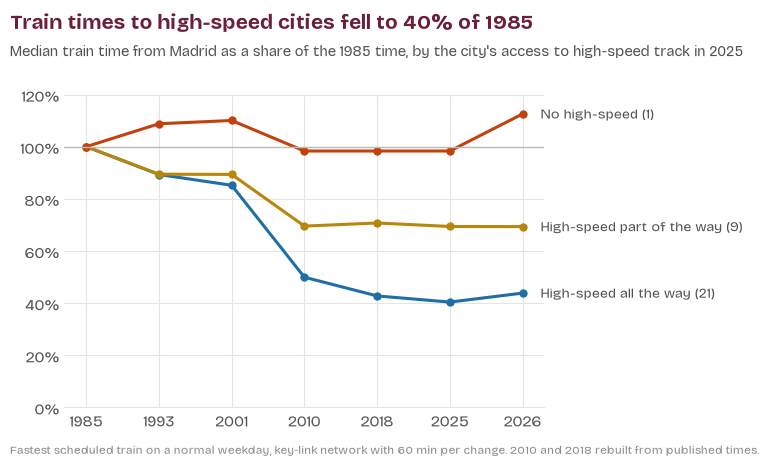

In [4]:
share = pd.DataFrame({e: mad[e] / mad["1985"] for e in ERAS})
share["access"] = mad["access"]
med = share.groupby("access")[ERAS].median().loc[GROUPS]
print(med.round(2).to_string())
print(f"cities per group: {mad['access'].value_counts().loc[GROUPS].to_dict()}")
xpos = list(range(len(ERAS)))  # <- eras evenly spaced, as on the page

fig, ax = plt.subplots(figsize=(FIG_W, 4.6))
fig.subplots_adjust(left=0.08, right=0.68, top=0.80, bottom=0.12)
for g in GROUPS:
    ax.plot(xpos, med.loc[g].values * 100, color=GROUP_COLOUR[g], linewidth=2.2, marker="o", markersize=5)
    n = int((mad["access"] == g).sum())
    ax.text(len(ERAS) - 1 + 0.25, med.loc[g, "2026"] * 100, f"{GROUP_LABEL[g]} ({n})", va="center", fontsize=10, color=TEXT)
ax.set_ylim(0, 120)
ax.set_yticks([0, 20, 40, 60, 80, 100, 120])
ax.set_yticklabels([f"{v}%" for v in [0, 20, 40, 60, 80, 100, 120]])
ax.set_xticks(xpos)
ax.set_xticklabels(ERAS)
ax.tick_params(length=0)
ax.axhline(100, color="#bdbcb6", linewidth=1)
titles(fig, "Train times to high-speed cities fell to 40% of 1985", "Median train time from Madrid as a share of the 1985 time, by the city's access to high-speed track in 2025")
source(fig, "Fastest scheduled train on a normal weekday, key-link network with 60 min per change. 2010 and 2018 rebuilt from published times.")
fig.savefig(OUT_DIR / "cs_f1_groups.png", dpi=DPI)
plt.show()

## 4. Finding 2: how far the high-speed line reaches matters

Every city's 2025 time from Madrid as a share of its 1985 time.

         city access  1985  2025  2026  share_2025  share_2026
    Tarragona   full 421.0 124.0 147.0       0.295       0.349
   Valladolid   full 170.0  54.0  54.0       0.318       0.318
    Barcelona   full 441.0 157.0 182.0       0.356       0.413
       Málaga   full 439.0 159.0 164.0       0.362       0.374
       Girona   full 571.0 208.0 243.0       0.364       0.426
      Ourense   full 365.0 134.0 134.0       0.367       0.367
      Córdoba   full 280.0 104.0 104.0       0.371       0.371
       Lleida   full 325.0 122.0 143.0       0.375       0.440
     Santiago   full 472.0 180.0 177.0       0.381       0.375
     Zaragoza   full 202.0  78.0  95.0       0.386       0.470
     Valencia   full 282.0 114.0 114.0       0.404       0.404
     A Coruña   full 530.0 214.0 214.0       0.404       0.404
      Sevilla   full 356.0 158.0 156.0       0.444       0.438
         León   full 259.0 116.0 116.0       0.448       0.448
  Ciudad Real   full 117.0  54.0  53.0       0.462     

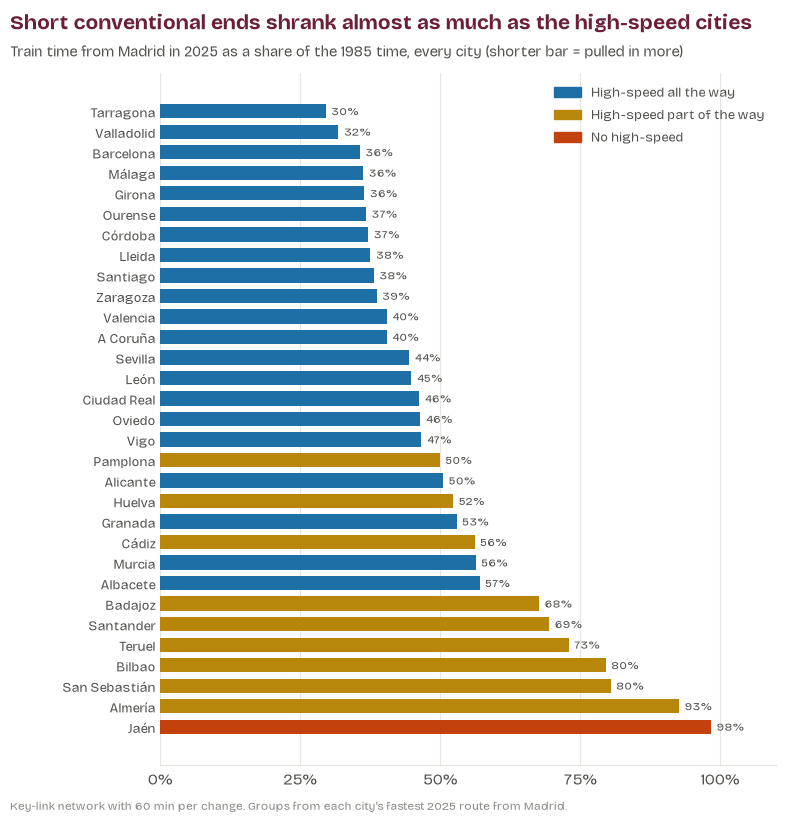

In [5]:
c = mad[["city", "access", "1985", "2025", "2026", "share_2025", "share_2026"]].sort_values("share_2025").reset_index(drop=True)
print(c.to_string(index=False))
part = c[c["access"] == "part"]
print("part-way cities, share 2025:", dict(zip(part["city"], part["share_2025"])))

fig, ax = plt.subplots(figsize=(FIG_W, 8.2))
fig.subplots_adjust(left=0.20, right=0.97, top=0.915, bottom=0.07)
y = np.arange(len(c))
ax.barh(y, c["share_2025"] * 100, color=[GROUP_COLOUR[a] for a in c["access"]], height=0.7)
for yi, v in zip(y, c["share_2025"]):
    ax.text(v * 100 + 1, yi, f"{v * 100:.0f}%", va="center", fontsize=8.5, color=TEXT)
ax.set_yticks(y)
ax.set_yticklabels(c["city"], fontsize=9.5)
ax.invert_yaxis()
ax.set_xlim(0, 110)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"])
ax.tick_params(length=0)
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLOUR[g]) for g in GROUPS]
ax.legend(handles, [GROUP_LABEL[g] for g in GROUPS], loc="upper right", frameon=False, fontsize=9.5)
titles(fig, "Short conventional ends shrank almost as much as the high-speed cities", "Train time from Madrid in 2025 as a share of the 1985 time, every city (shorter bar = pulled in more)")
source(fig, "Key-link network with 60 min per change. Groups from each city's fastest 2025 route from Madrid.")
fig.savefig(OUT_DIR / "cs_f2_cities.png", dpi=DPI)
plt.show()

## 5. Finding 3: against the car

Car time / train time from Madrid, 2025 (full timetable for the train, OSRM free-flow driving for the car). Above 1: the train is faster.

         city access  road_min  rail_2025  rail_2026  ratio_2025  ratio_2026  ratio_sens_2025  ratio_race_2025
    Tarragona   full    357.53      124.0      147.0        2.88        2.43             2.58             2.74
  Ciudad Real   full    149.01       54.0       53.0        2.76        2.81             2.01             2.62
   Valladolid   full    148.33       54.0       54.0        2.75        2.75             2.00             2.61
     Zaragoza   full    212.20       78.0       95.0        2.72        2.23             2.15             2.58
    Barcelona   full    405.40      157.0      182.0        2.58        2.23             2.49             2.45
      Córdoba   full    266.77      104.0      104.0        2.56        2.56             2.29             2.43
       Lleida   full    306.27      122.0      143.0        2.51        2.14             2.28             2.38
      Ourense   full    336.23      134.0      134.0        2.51        2.51             2.29             2.38
 

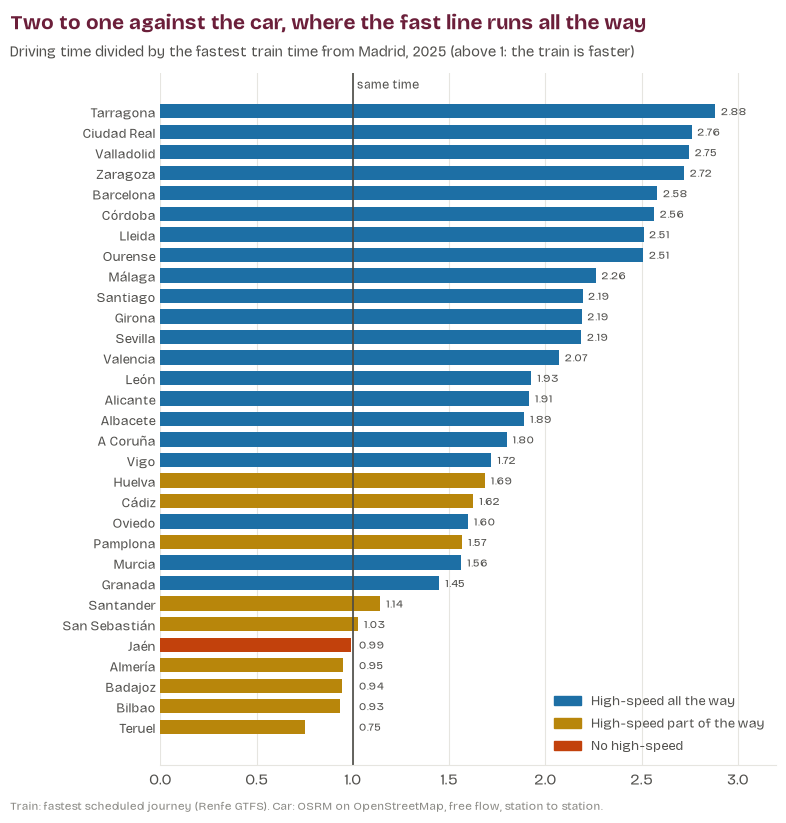

In [6]:
r = road[["city", "access", "road_min", "rail_2025", "rail_2026", "ratio_2025", "ratio_2026", "ratio_sens_2025", "ratio_race_2025"]].sort_values("ratio_2025", ascending=False).reset_index(drop=True)
print(r.round(2).to_string(index=False))
print("median car / train by group:")
print(road.groupby("access")[["ratio_2025", "ratio_2026"]].median().loc[GROUPS].round(2).to_string())
for era in ["2025", "2026"]:
    print(f"{era}: train faster to {(road[f'ratio_{era}'] > 1).sum()} of {len(road)} cities from Madrid; all pairs: {pairs[f'train_wins_{era}'].sum()} of {len(pairs)} ({pairs[f'train_wins_{era}'].mean():.0%}; from 07road's unrounded ratios)")
print(f"sensitivities 2025 from Madrid: {(road['ratio_sens_2025'] > 1).sum()} (train + 30 min, car + breaks), {(road['ratio_race_2025'] > 1).sum()} (car scaled to RACE)")

fig, ax = plt.subplots(figsize=(FIG_W, 8.2))
fig.subplots_adjust(left=0.20, right=0.97, top=0.915, bottom=0.07)
y = np.arange(len(r))
ax.barh(y, r["ratio_2025"], color=[GROUP_COLOUR[a] for a in r["access"]], height=0.7)
for yi, v in zip(y, r["ratio_2025"]):
    ax.text(max(v, 1.0) + 0.03, yi, f"{v:.2f}", va="center", fontsize=8.5, color=TEXT)
ax.axvline(1, color="#4a4945", linewidth=1.2)
ax.text(1.02, -1.1, "same time", fontsize=9, color=TEXT)
ax.set_yticks(y)
ax.set_yticklabels(r["city"], fontsize=9.5)
ax.invert_yaxis()
ax.set_xlim(0, 3.2)
ax.tick_params(length=0)
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLOUR[g]) for g in GROUPS]
ax.legend(handles, [GROUP_LABEL[g] for g in GROUPS], loc="lower right", frameon=False, fontsize=9.5)
titles(fig, "Two to one against the car, where the fast line runs all the way", "Driving time divided by the fastest train time from Madrid, 2025 (above 1: the train is faster)")
source(fig, "Train: fastest scheduled journey (Renfe GTFS). Car: OSRM on OpenStreetMap, free flow, station to station.")
fig.savefig(OUT_DIR / "cs_f3_car.png", dpi=DPI)
plt.show()

## 6. Finding 4: the 2026 slowdown on Madrid to Barcelona (numbers from 09marey)

In [7]:
print(mstats.to_string())
print()
print(f"fastest: {hm(float(mstats['fastest_min_before']))} (Renfe, 14 Jan 2026) -> {hm(float(mstats['fastest_min']))} (25 Nov 2026), +{float(mstats['fastest_min']) - float(mstats['fastest_min_before']):.0f} min")
print(f"Renfe median: {hm(float(mstats['median_min_before_renfe']))} -> {hm(float(mstats['median_min_renfe']))}, +{float(mstats['median_min_renfe']) - float(mstats['median_min_before_renfe']):.0f} min")
print("2026 against 2025 from Madrid (map measure), minutes:")
d = mad[["city", "2025", "2026"]].assign(change=mad["2026"] - mad["2025"]).sort_values("change", ascending=False)
print(d.head(10).to_string(index=False))

key
trains_total                  89
trains_renfe                  51
trains_iryo                   28
trains_ouigo                  10
share_new_operators        0.427
nonstop_trains                32
fastest_min                182.0
median_min                 197.0
slowest_min                230.0
fastest_min_before         157.0
median_min_before_renfe    173.0
median_min_renfe           197.0
nonstop_kmh                  205
nonstop_kmh_before           237
busiest_hour_barcelona      6:00
shortest_gap_barcelona       4.0
overtakes_barcelona            9
busiest_hour_madrid         7:00
shortest_gap_madrid          5.0
overtakes_madrid               8

fastest: 2 h 37 (Renfe, 14 Jan 2026) -> 3 h 02 (25 Nov 2026), +25 min
Renfe median: 2 h 53 -> 3 h 17, +24 min
2026 against 2025 from Madrid (map measure), minutes:
     city  2025  2026  change
   Girona 208.0 243.0    35.0
     Jaén 235.0 269.0    34.0
Barcelona 157.0 182.0    25.0
Tarragona 124.0 147.0    23.0
   Lleida 122.0 143.0

___
**END**